In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load your dataset if it is not already loaded
df = pd.read_csv('/home/ninelaps/uber-ml/data/csv/deliveries.csv')

# Check rows and columns
print("Dataset shape:", df.shape)

# View sample records
print(df.head())

# Check column names and data types
print(df.info())

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check numerical statistics
print(df.describe())

Dataset shape: (47851, 14)
  delivery_id  order_id driver_id restaurant_id customer_id  \
0   DL0000001  O0000001    D00256        R00110     C001387   
1   DL0000002  O0000002    D00171        R00440     C007734   
2   DL0000003  O0000003    D00302        R00244     C006407   
3   DL0000004  O0000004    D00256        R00496     C007317   
4   DL0000005  O0000005    D00148        R00415     C006043   

                pickup_timestamp              dropoff_timestamp  \
0  2026-09-01 11:18:42.109794794  2026-09-01 11:26:42.109794794   
1  2026-08-07 21:07:44.218047814  2026-08-07 21:38:44.218047814   
2  2026-10-16 16:02:26.799930150  2026-10-16 16:18:26.799930150   
3  2026-09-05 19:40:50.630293888  2026-09-05 20:08:50.630293888   
4  2026-08-25 17:18:32.640509204  2026-08-25 17:51:32.640509204   

   delivery_distance_km  preparation_time_min  delivery_time_min  \
0                  1.48                    11                8.4   
1                  5.15                    24          

count    45410.000000
mean        29.293821
std         12.308496
min          8.000000
25%         21.000000
50%         27.500000
75%         35.400000
max         95.000000
Name: delivery_time_min, dtype: float64


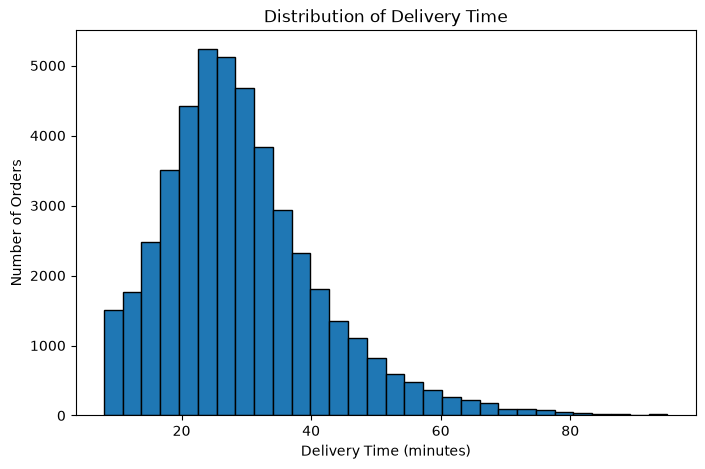

/tmp/ipykernel_4668/1778710206.py:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[target].dropna(), vert=True)


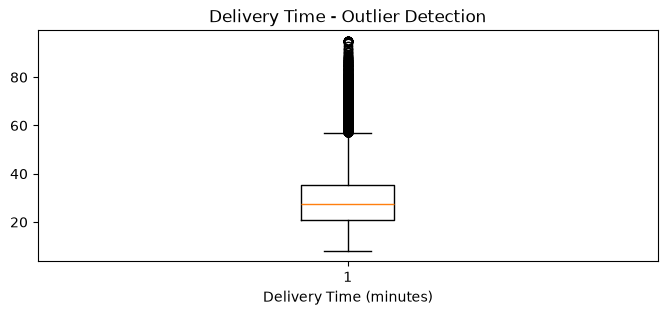

In [3]:
target = 'delivery_time_min'

print(df[target].describe())

# Histogram
plt.figure(figsize=(8, 5))
plt.hist(df[target].dropna(), bins=30, edgecolor='black')
plt.title('Distribution of Delivery Time')
plt.xlabel('Delivery Time (minutes)')
plt.ylabel('Number of Orders')
plt.show()

# Box plot
plt.figure(figsize=(8, 3))
plt.boxplot(df[target].dropna(), vert=True)
plt.title('Delivery Time - Outlier Detection')
plt.xlabel('Delivery Time (minutes)')
plt.show()

In [4]:
Q1 = df[target].quantile(0.25)
Q3 = df[target].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df[target] < lower_limit) |
    (df[target] > upper_limit)
]

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Number of potential outliers:", len(outliers))

print(outliers[[target]].head(10))

Lower limit: -0.5999999999999979
Upper limit: 57.0
Number of potential outliers: 1466
     delivery_time_min
73                65.2
76                68.4
102               77.0
132               59.6
187               73.5
194               86.6
238               58.0
307               68.4
320               63.2
405               76.4


In [5]:
numeric_df = df.select_dtypes(include='number')

correlations = numeric_df.corr(numeric_only=True)

if target in correlations.columns:
    print(
        correlations[target]
        .sort_values(ascending=False)
    )

delivery_time_min       1.000000
total_time_min          0.880345
delivery_distance_km    0.649572
preparation_time_min   -0.008364
tip_amount             -0.228794
Name: delivery_time_min, dtype: float64


In [6]:
features = [
    'delivery_distance',
    'order_amount',
    'number_of_items',
    'preparation_time'
]

for col in features:
    if col in df.columns:
        plot_data = df[[col, target]].dropna()

        plt.figure(figsize=(7, 4))
        plt.scatter(plot_data[col], plot_data[target], alpha=0.5)
        plt.title(f'{col} vs Delivery Time')
        plt.xlabel(col)
        plt.ylabel('Delivery Time (minutes)')
        plt.show()

In [7]:
features_to_check = [
    col for col in [
        'delivery_distance',
        'order_amount',
        'number_of_items',
        'preparation_time'
    ]
    if col in df.columns
]

if features_to_check:
    print(
        df.nlargest(10, target)[features_to_check + [target]]
    )

In [8]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge, Lasso
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --------------------------------------------------
# PREPARE DATA
# --------------------------------------------------

target = 'delivery_time_min'

# Remove rows where target is missing
data = df.dropna(subset=[target]).copy()

# Remove invalid negative delivery times
data = data[data[target] >= 0]

# Exclude target, ID columns, and datetime columns from features
exclude_cols = [
    col for col in data.columns
    if col == target
    or 'id' in col.lower()
    or 'timestamp' in col.lower()
    or 'datetime' in col.lower()
]

X = data.drop(columns=exclude_cols)
y = data[target]

# Remove columns containing only missing values
X = X.dropna(axis=1, how='all')

# Separate numerical and categorical columns
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("Number of records:", len(data))
print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

# Train/test split: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# --------------------------------------------------
# PREPROCESSING
# --------------------------------------------------

# Numerical preprocessing for Ridge and Lasso
numeric_scaled = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Numerical preprocessing for Baseline and Random Forest
numeric_tree = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

# Categorical preprocessing
categorical_process = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Preprocessing for linear models
preprocess_linear = ColumnTransformer([
    ('num', numeric_scaled, numeric_features),
    ('cat', categorical_process, categorical_features)
])

# Preprocessing for tree and baseline models
preprocess_tree = ColumnTransformer([
    ('num', numeric_tree, numeric_features),
    ('cat', categorical_process, categorical_features)
])






Number of records: 45410
Numerical features: ['delivery_distance_km', 'preparation_time_min', 'total_time_min', 'tip_amount']
Categorical features: ['vehicle_type', 'on_time_flag']


/tmp/ipykernel_4668/3351838126.py:40: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [9]:
# --------------------------------------------------
# PART 2: BASELINE REGRESSION
# --------------------------------------------------

baseline = Pipeline([
    ('preprocessing', preprocess_tree),
    ('model', DummyRegressor(strategy='mean'))
])



In [10]:
# --------------------------------------------------
# PART 3: RANDOM FOREST
# --------------------------------------------------

random_forest = Pipeline([
    ('preprocessing', preprocess_tree),
    ('model', RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])



In [11]:
# --------------------------------------------------
# PART 4: RIDGE AND LASSO
# --------------------------------------------------

ridge = Pipeline([
    ('preprocessing', preprocess_linear),
    ('model', Ridge(alpha=1.0))
])

lasso = Pipeline([
    ('preprocessing', preprocess_linear),
    ('model', Lasso(alpha=0.1, max_iter=10000))
])

models = {
    'Baseline': baseline,
    'Random Forest': random_forest,
    'Ridge': ridge,
    'Lasso': lasso
}


In [12]:
# --------------------------------------------------
# PART 5: TRAIN AND EVALUATE
# --------------------------------------------------

results = []

for name, model in models.items():

    # Train model
    model.fit(X_train, y_train)

    # Predictions on train and test data
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    # Training scores help identify overfitting
    train_mae = mean_absolute_error(y_train, train_pred)

    # Test scores measure performance on unseen data
    mae = mean_absolute_error(y_test, test_pred)
    rmse = np.sqrt(mean_squared_error(y_test, test_pred))
    r2 = r2_score(y_test, test_pred)

    results.append({
        'Model': name,
        'Train MAE': train_mae,
        'Test MAE': mae,
        'Test RMSE': rmse,
        'Test R2': r2
    })

results_df = pd.DataFrame(results).sort_values('Test MAE')

print("\nMODEL COMPARISON")
print(results_df.round(3).to_string(index=False))



MODEL COMPARISON
        Model  Train MAE  Test MAE  Test RMSE  Test R2
        Ridge      0.001     0.001      0.001    1.000
Random Forest      0.059     0.114      0.334    0.999
        Lasso      0.150     0.152      0.196    1.000
     Baseline      9.344     9.416     12.365   -0.000


In [13]:
# --------------------------------------------------
# CROSS-VALIDATION: RANDOM FOREST
# --------------------------------------------------

cv_scores = cross_val_score(
    random_forest,
    X_train,
    y_train,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=1
)

print("\nRandom Forest 5-Fold CV MAE:", round(-cv_scores.mean(), 3))
print("CV MAE standard deviation:", round(cv_scores.std(), 3))


Random Forest 5-Fold CV MAE: 0.14
CV MAE standard deviation: 0.009



TOP 10 IMPORTANT FEATURES
                  Feature  Importance
   cat__on_time_flag_True    0.425242
      num__total_time_min    0.209525
num__delivery_distance_km    0.154859
  cat__on_time_flag_False    0.133916
num__preparation_time_min    0.074608
cat__vehicle_type_Bicycle    0.001257
    cat__vehicle_type_Car    0.000302
          num__tip_amount    0.000261
cat__vehicle_type_Scooter    0.000030


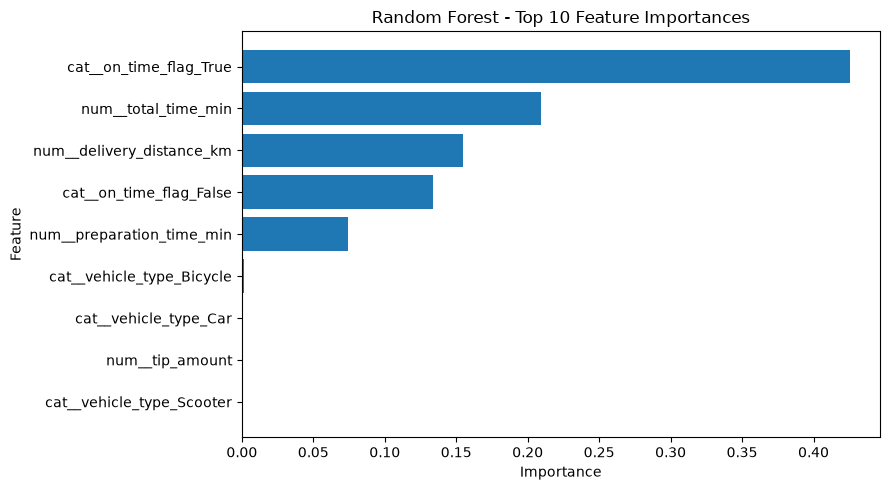

In [14]:
# --------------------------------------------------
# RANDOM FOREST FEATURE IMPORTANCE
# --------------------------------------------------

rf_model = random_forest.named_steps['model']
rf_preprocessor = random_forest.named_steps['preprocessing']

feature_names = rf_preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

print("\nTOP 10 IMPORTANT FEATURES")
print(importance_df.head(10).to_string(index=False))

# Plot feature importance
top_features = importance_df.head(10).sort_values('Importance')

plt.figure(figsize=(9, 5))
plt.barh(top_features['Feature'], top_features['Importance'])
plt.title('Random Forest - Top 10 Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()



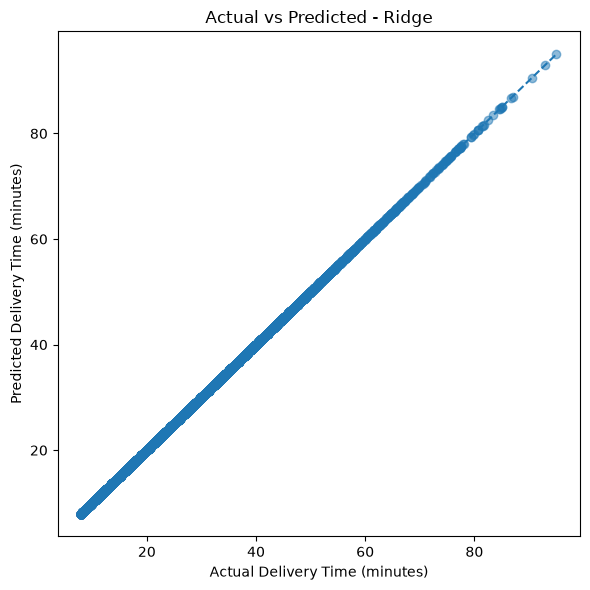


Best model based on test MAE: Ridge


In [15]:
# --------------------------------------------------
# ACTUAL VS PREDICTED: BEST MODEL
# --------------------------------------------------

best_name = results_df.iloc[0]['Model']
best_model = models[best_name]
best_predictions = best_model.predict(X_test)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_predictions, alpha=0.5)

min_val = min(y_test.min(), best_predictions.min())
max_val = max(y_test.max(), best_predictions.max())

plt.plot([min_val, max_val], [min_val, max_val], linestyle='--')
plt.xlabel('Actual Delivery Time (minutes)')
plt.ylabel('Predicted Delivery Time (minutes)')
plt.title(f'Actual vs Predicted - {best_name}')
plt.tight_layout()
plt.show()

print("\nBest model based on test MAE:", best_name)

In [16]:
delivery_results = pd.DataFrame({
    "actual_delivery_time": y_test.values,
    "predicted_delivery_time": best_model.predict(X_test)
})

delivery_results.to_csv("delivery_predictions.csv", index=False)